# Nested sampling of a planet's orbit with Gaia astrometry and radial velocities

Notebook 03 found the planet with `fit_astrometry_and_rv_planets` (a periodogram search, then a best fit) and sampled the posterior with MCMC, started at the best fit. This notebook samples the same posterior with nested sampling ([dynesty](https://dynesty.readthedocs.io); Speagle 2020), starting from the prior (the best fit only centers the ranges of the angles). Nested sampling explores the whole prior, so it finds every significant mode of the posterior (e.g. aliases of the period, or both modes of an ambiguous inclination), and it needs no starting point, burn-in or convergence checks; it also gives the evidence (not used here). The price is more likelihood evaluations than an MCMC started at the best fit. This notebook
1. simulates the Gaia DR5 astrometry and RVs of notebook 03 (the same data),
2. defines physical priors, and the likelihood with gaiamockplus' `log_likelihood_astrometry_and_rv_planets`, which integrates out the parameters on which the model depends linearly,
3. samples the posterior with dynesty, and
4. shows the posterior (corner plot) and the orbit and RVs of the posterior sample with the highest likelihood.

It needs `gaiamockplus`, `dynesty` and `corner`. The nested sampling takes about 2 minutes.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import dynesty
import corner
from scipy.stats import beta
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(6)            # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the astrometry and the RVs

As in notebook 03 (the same code and random seed): a 3 $M_\mathrm{J}$ planet on a 9 yr orbit around a 0.8 $M_\odot$ star at 100 pc, with Gaia DR5 astrometry and 22 RVs from three instruments (with 3 m/s of jitter).

In [2]:
# the star and the planet: as in notebook 01, with a 3 Jupiter-mass planet
m_star = 0.8               # Msun
parallax = 10.0            # mas
phot_g_mean_mag = 11.1     # G magnitude of a 0.8 Msun main-sequence star at 100 pc
ra, dec = 25.0, -13.0      # deg
pmra, pmdec = 12.0, 30.0   # mas/yr
planet = dict(period=365.25*4.0**1.5/np.sqrt(m_star), Tp=500.0, ecc=0.2,
              Omega=np.radians(110.0), inc=np.radians(60.0), w=np.radians(50.0), m_planet=3*M_JUP)

# Gaia astrometry
ast_data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                          planets=[planet], phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                          c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = ast_data

# three RV datasets: number of RVs, formal uncertainty (km/s), and time range (yr, relative to the reference epoch)
n_rv = [5, 7, 10]
rv_err_set = [0.007, 0.010, 0.010]
time_ranges = [(-10, -4), (-5, 1), (0, 7)]
gamma = np.array([-12.405, -12.380, -12.420])  # systemic velocity of each dataset (km/s)
jitter = 0.003                                 # km/s

t_rvs_yr = np.concatenate([np.sort(rng.uniform(*r, n)) for r, n in zip(time_ranges, n_rv)])
rv_dataset = np.repeat([0, 1, 2], n_rv)        # the dataset of each RV
rv_err = np.repeat(rv_err_set, n_rv)           # formal uncertainties
rv = (gmp.rv_planets_model(t_rvs_yr, m_star, [planet], gamma, c_funcs, rv_dataset=rv_dataset)
      + np.sqrt(rv_err**2 + jitter**2)*rng.normal(0, 1, len(t_rvs_yr)))
rv_data = (t_rvs_yr, rv, rv_err)

a0_true, K_true = gmp.get_planet_a0_mas(m_star, [planet], parallax)[0], gmp.get_planet_K_kms(m_star, [planet])[0]
print(f'astrometry: {len(t_ast_yr)} transits, a0 = {a0_true:.3f} mas, median uncertainty {np.median(ast_err):.3f} mas')
print(f'RVs: {len(rv)} in {len(n_rv)} datasets, K = {1e3*K_true:.1f} m/s')

astrometry: 170 transits, a0 = 0.143 mas, median uncertainty 0.047 mas
RVs: 22 in 3 datasets, K = 42.0 m/s


## 2. Priors and likelihood

As in notebook 03's MCMC, `log_likelihood_astrometry_and_rv_planets` integrates out, analytically and with flat priors, the parameters on which the model depends linearly: the position offsets $\Delta\alpha^*$, $\Delta\delta$, the proper motion $\mu_{\alpha^*}$, $\mu_\delta$ and the systemic velocity of each RV dataset. So dynesty samples only 12 parameters instead of 19, and afterwards `expand_marginal_samples` draws the integrated-out parameters of each sample from their (Gaussian) conditional posterior. The sampled parameters are the likelihood's, except that the planet's mass replaces $a_0$ (which follows from the mass, period, parallax and stellar mass), and the phase is sampled as $\lambda_0 = \omega - \phi_p$, which the data constrain even when $\phi_p$ and $\omega$ are individually poorly constrained (at low eccentricity), with $\phi_p = \omega - \lambda_0$. The priors:

| parameter | prior |
|---|---|
| parallax $\varpi$ | uniform, within 2 mas of the no-planet solution |
| period $P$ | log-uniform, 1 to 30 yr |
| eccentricity $e$ | Beta(0.867, 3.03) (Kipping 2013) |
| $\lambda_0$, $\Omega$, $\omega$ | uniform over $2\pi$, centered on the best fit (the same prior as uniform $\phi_p$, $\Omega$, $\omega$) |
| inclination $i$ | isotropic ($\cos i$ uniform between -1 and 1) |
| planet mass $m_p$ | log-uniform, 0.3 to 30 $M_\mathrm{J}$ |
| RV jitter of each dataset | uniform, 0 to 20 m/s |
| astrometric jitter $s$ | uniform, 0 to 0.1 mas |
| position offsets, proper motion, systemic velocities | flat (integrated out) |

The no-planet solution (from `get_astrometric_chi2_planets` with no planets) only centers the parallax prior: the planet's reflex orbit shifts it by about its size (0.14 mas here), far less than the prior range. The best fit (`fit_astrometry_and_rv_planets`, as in notebook 03) only centers the ranges of the angles: a range of $2\pi$ centered anywhere is the same uniform prior, but centering it on the best fit keeps a well-constrained angle away from the edges of dynesty's unit cube, where its posterior would be split in two (the bounding ellipsoids that dynesty fits to the live points do not wrap around). dynesty draws points in the unit cube, which `prior_transform` maps to the parameters, and `to_theta` turns them into the likelihood's parameter vector. The flat priors of the integrated-out parameters give the same posterior as uniform priors over any ranges that contain it, e.g. within 2 mas (mas/yr) of the no-planet solution for the position offsets and proper motion and within 100 m/s of each dataset's mean RV; the evidence for such priors is that of the run divided by their volume, `ln_volume`.

In [3]:
# the parallax of the no-planet solution, to center its prior, and the best fit, to center the ranges of the angles
plx0 = gmp.get_astrometric_chi2_planets(*ast_data, [], [], [])[1][4]
res_fit = gmp.fit_astrometry_and_rv_planets(*ast_data, *rv_data, rv_dataset=rv_dataset, n_planets=1, m_star=m_star)
best = dict(zip(res_fit['theta_names'], res_fit['theta']))
centers = np.array([best['w_0'] - best['phi_p_0'], best['Omega_0'], best['w_0']])  # lambda_0, Omega, w

names = ['parallax', 'P', 'e', 'lambda_0', 'Omega', 'inc', 'w', 'm_p', 'jitter_0', 'jitter_1', 'jitter_2', 'ast_jitter']
ndim = len(names)

def prior_transform(u):
    '''parameters (gaiamock units: mas, days, radians, Msun, km/s) from a point u in the unit cube'''
    x = np.empty(ndim)
    x[0] = plx0 + 4*(u[0] - 0.5)                                           # parallax: within 2 mas
    x[1] = 365.25*np.exp(np.log(1.0) + (np.log(30.0) - np.log(1.0))*u[1])  # P: log-uniform, 1 to 30 yr
    x[2] = beta.ppf(u[2], 0.867, 3.03)                                     # e
    x[[3, 4, 6]] = centers + 2*np.pi*(u[[3, 4, 6]] - 0.5)                 # lambda_0 = w - phi_p, Omega, w: within pi of the best fit
    x[5] = np.arccos(1 - 2*u[5])                                           # inc: isotropic
    x[7] = M_JUP*np.exp(np.log(0.3) + (np.log(30.0) - np.log(0.3))*u[7])   # m_p: log-uniform, 0.3 to 30 M_Jup
    x[8:11] = 0.02*u[8:11]                                                 # RV jitters: 0 to 0.02 km/s
    x[11] = 0.1*u[11]                                                      # astrometric jitter: 0 to 0.1 mas
    return x

def to_theta(x):
    '''the likelihood's parameters (parallax, P, e, phi_p, Omega, inc, w, a0, the jitters): phi_p = w - lambda_0, a0 from the planet mass'''
    plx, P, e, lambda_0, Omega, inc, w, m_p = x[:8]
    a0 = gaiamock.get_a0_mas(period=P, m1=m_star, m2=m_p, parallax=plx, f=0.0)
    return np.concatenate([[plx, P, e, w - lambda_0, Omega, inc, w, a0], x[8:]])

def log_like(x):
    return gmp.log_likelihood_astrometry_and_rv_planets(to_theta(x), *ast_data, *rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True)

# for the evidence: the volume of uniform priors on the integrated-out parameters (4 mas and 4 mas/yr wide, and 0.2 km/s wide for each dataset)
ln_volume = 4*np.log(4.0) + 3*np.log(0.2)

## 3. Nested sampling

The sampler keeps 400 "live" points drawn from the prior and repeatedly replaces the one with the lowest likelihood by a new point of higher likelihood, so the live points contract onto the posterior. New points are found within multiple ellipsoids that bound the live points (`bound='multi'`), with slice sampling (`sample='rslice'`; in our tests with all 19 parameters sampled, dynesty's random-walk sampler gave posteriors up to ~30% too narrow). The angles $\lambda_0$, $\Omega$ and $\omega$ are periodic. The run stops with dynesty's default criterion (the estimated remaining evidence is small).

In [4]:
sampler = dynesty.NestedSampler(log_like, prior_transform, ndim, nlive=400, bound='multi', sample='rslice', periodic=[3, 4, 6],
                                rstate=np.random.default_rng(6))
start = time.time()
sampler.run_nested(print_progress=False)
runtime = time.time() - start
res = sampler.results
print(f'{runtime/60:.1f} minutes: {res.niter} iterations, {np.sum(res.ncall)} likelihood evaluations')
print(f'ln(evidence) = {res.logz[-1] - ln_volume:.2f} +/- {res.logzerr[-1]:.2f} (with the uniform priors above on the integrated-out parameters); '
      f'information H = {res.information[-1]:.0f} nats')

1.8 minutes: 12017 iterations, 877675 likelihood evaluations
ln(evidence) = 287.38 +/- 0.38 (with the uniform priors above on the integrated-out parameters); information H = 23 nats


## 4. The posterior

The nested-sampling points carry weights; `samples_equal` resamples them into equally weighted posterior samples of the sampled parameters. As in notebook 03, the planet mass and the Campbell elements are shown, with the parallax relative to the no-planet solution; the red lines mark the true values.

12417 samples (effective sample size 3720)


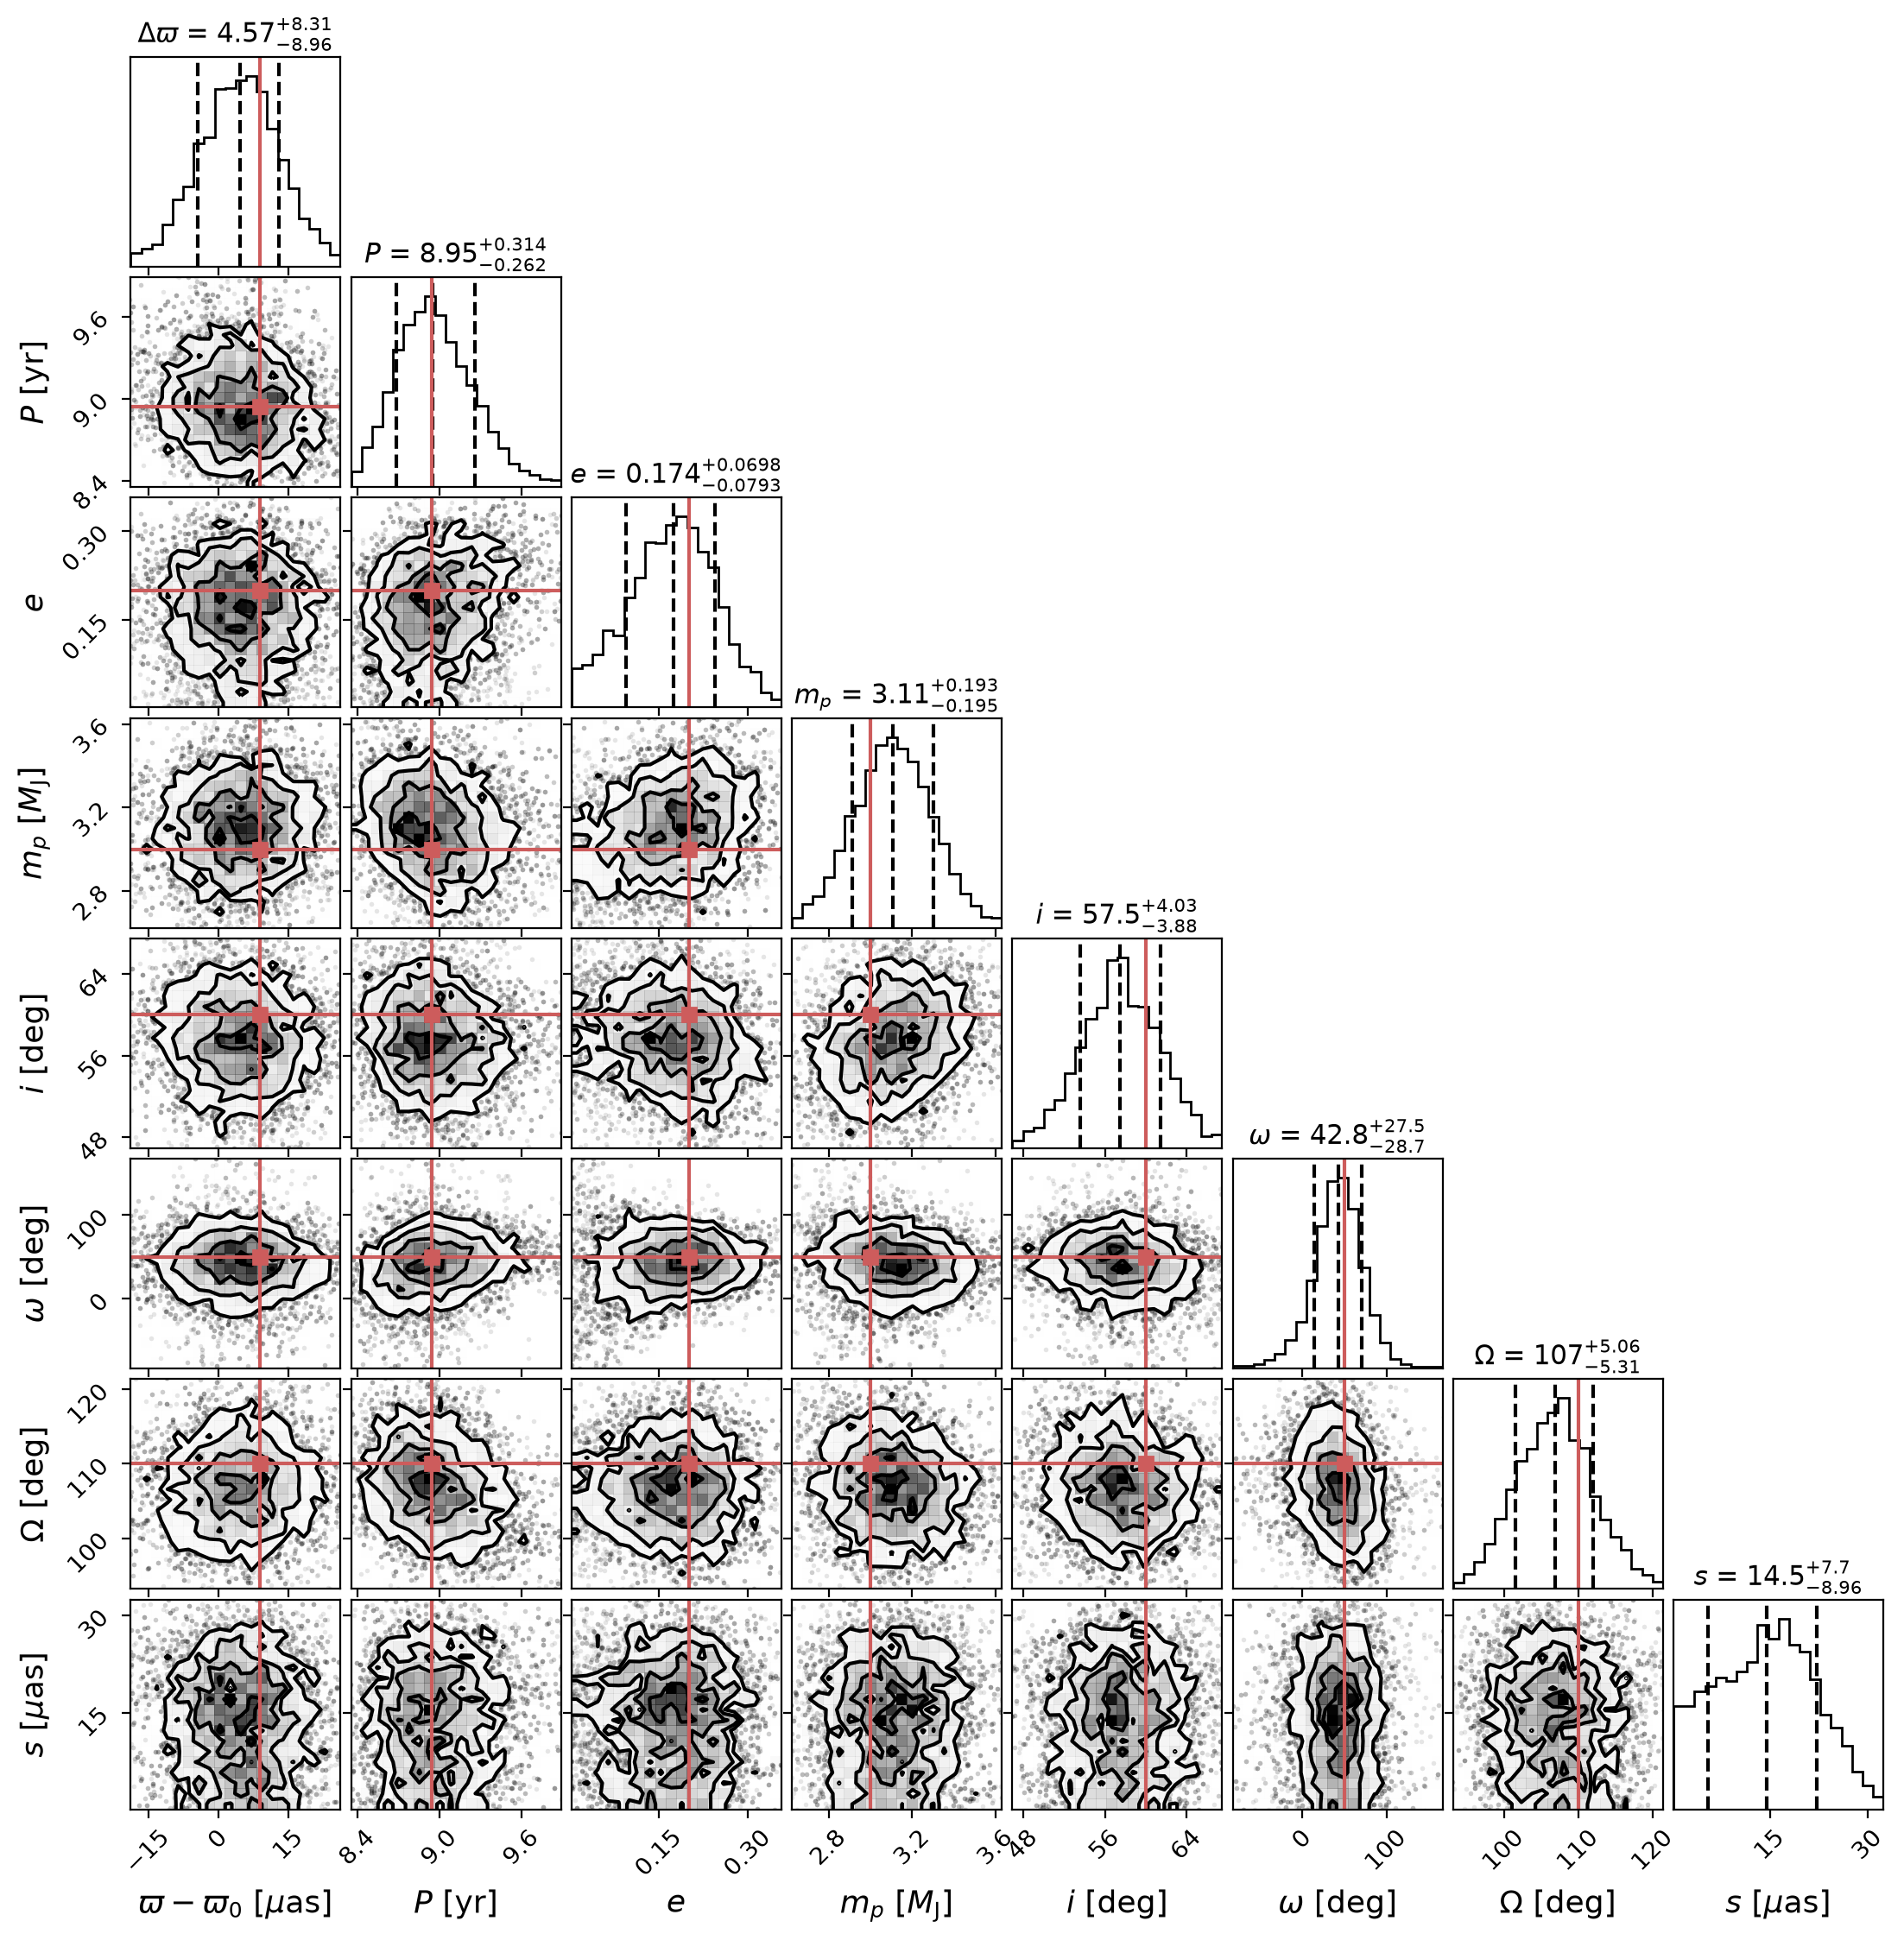

RV jitter [m/s] (true 3): dataset 0: 3.7 (+5.3 / -2.7), dataset 1: 3.7 (+4.6 / -2.7), dataset 2: 4.3 (+4.8 / -3.0)


In [5]:
x_s = res.samples_equal(rstate=np.random.default_rng(1))
weights = res.importance_weights()
print(f'{len(x_s)} samples (effective sample size {1/np.sum(weights**2):.0f})')

plx_s, P_s, e_s, Omega_s, inc_s, w_s, m_s = (x_s[:, k] for k in (0, 1, 2, 4, 5, 6, 7))
w_s = planet['w'] + np.angle(np.exp(1j*(w_s - planet['w'])))              # keep the angles continuous around the truth
Omega_s = planet['Omega'] + np.angle(np.exp(1j*(Omega_s - planet['Omega'])))

corner_samples = np.column_stack([1e3*(plx_s - plx0), P_s/365.25, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s),
                                  1e3*x_s[:, 11]])
labels = [r'$\varpi - \varpi_0$ [$\mu$as]', r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]',
          r'$s$ [$\mu$as]']
titles = [r'$\Delta\varpi$', r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$', r'$s$']
truths = [1e3*(parallax - plx0), planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, 60.0, 50.0, 110.0, None]
fig = corner.corner(corner_samples, range=[0.99]*corner_samples.shape[1], labels=labels, titles=titles, truths=truths, truth_color='indianred',
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08, label_kwargs=dict(fontsize=13),
                    title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

lo, med, hi = np.percentile(1e3*x_s[:, 8:11], [16, 50, 84], axis=0)
print('RV jitter [m/s] (true 3):', ', '.join(f'dataset {k}: {med[k]:.1f} (+{hi[k] - med[k]:.1f} / -{med[k] - lo[k]:.1f})' for k in range(3)))

`expand_marginal_samples` gives samples of all 19 parameters, ordered as `theta` of notebook 03's joint fit (with $a_0$), followed by the jitters; without a fit result, it takes the number of planets. Below, the sample with the highest likelihood: its photocenter orbit on the sky (as in notebook 03) and its RVs, with each dataset's systemic velocity subtracted (error bars: formal uncertainty and jitter in quadrature).

highest likelihood: P = 8.82 yr, e = 0.20, m_p = 3.21 M_Jup, inc = 58.0 deg


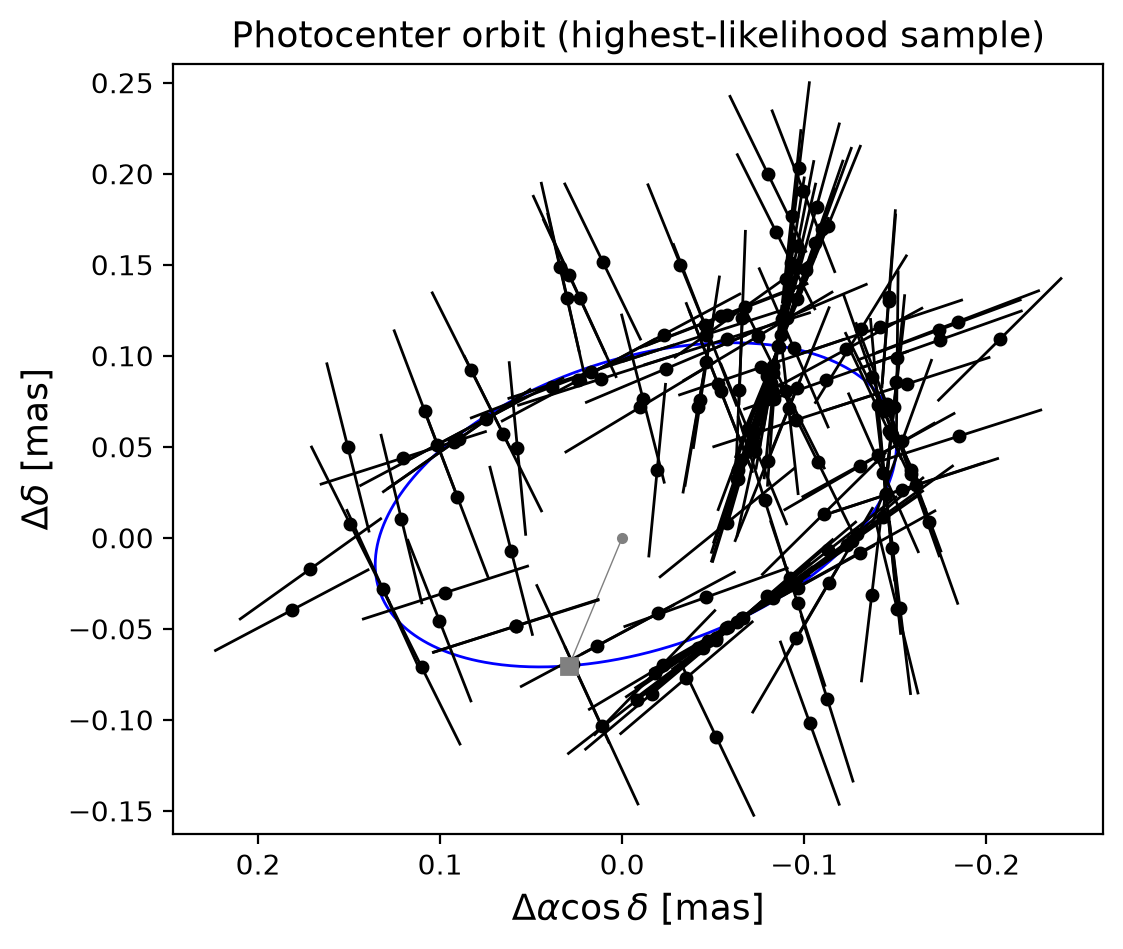

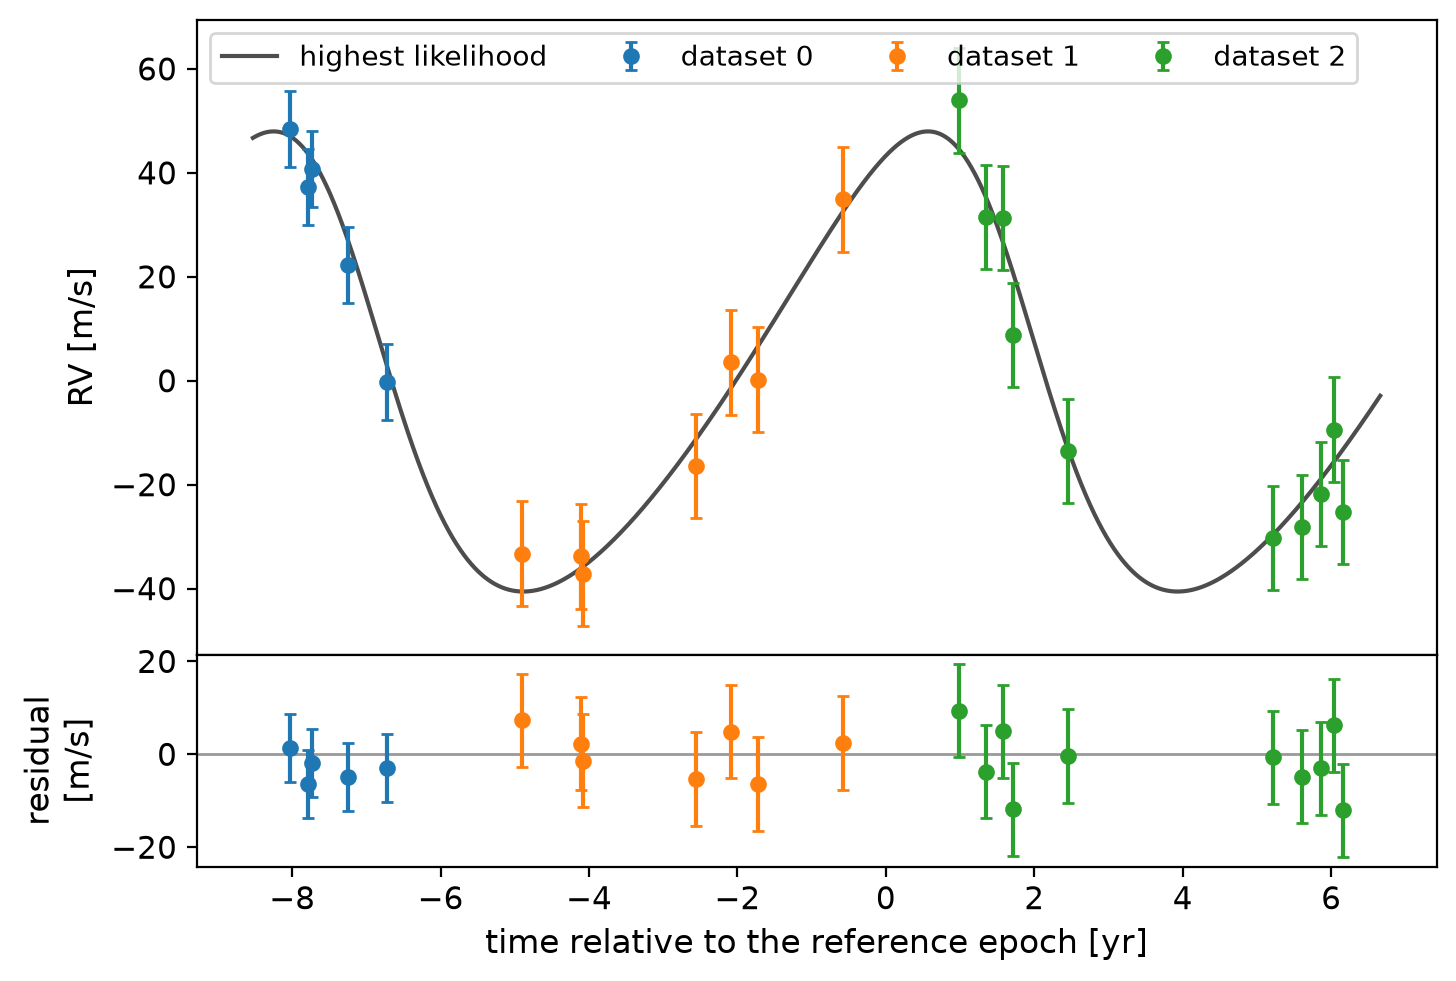

In [6]:
samples = gmp.expand_marginal_samples([to_theta(x) for x in x_s], ast_data=ast_data, rv_data=rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True,
                                     n_planets=1, rng=np.random.default_rng(2))
logl = [gmp.log_likelihood_astrometry_and_rv_planets(y, *ast_data, *rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True, marginalize=False)
        for y in samples]
i_best = np.argmax(logl)
x = samples[i_best]  # ra_off, dec_off, parallax, pmra, pmdec, P, e, phi_p, Omega, inc, w, a0, the systemic velocities, the jitters
best = dict(period=x[5], Tp=x[7]*x[5]/(2*np.pi), ecc=x[6], Omega=x[8], inc=x[9], w=x[10], m_planet=m_s[i_best])
print(f"highest likelihood: P = {x[5]/365.25:.2f} yr, e = {x[6]:.2f}, m_p = {m_s[i_best]/M_JUP:.2f} M_Jup, inc = {np.degrees(x[9]):.1f} deg")

A, B, F, G = gmp.get_thiele_innes(x[11], best['Omega'], best['inc'], best['w'])
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(*ast_data, period=best['period'], ecc=best['ecc'], Tp=best['Tp'], delta_ra=x[0], delta_dec=x[1],
                                     parallax=x[2], pmra=x[3], pmdec=x[4], A=A, B=B, F=F, G=G, data_release='dr5', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title('Photocenter orbit (highest-likelihood sample)', fontsize=13)
plt.show()

gamma_best, jitter_best = x[12:15], x[15:18]
t_grid = np.linspace(t_rvs_yr.min() - 0.5, t_rvs_yr.max() + 0.5, 2000)
curve = gmp.rv_planets_model(t_grid, m_star, [best], 0.0, c_funcs)
model = gmp.rv_planets_model(t_rvs_yr, m_star, [best], gamma_best, c_funcs, rv_dataset=rv_dataset)
err = np.sqrt(rv_err**2 + jitter_best[rv_dataset]**2)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0))
axes[0].plot(t_grid, 1e3*curve, color='0.3', lw=1.5, zorder=0, label='highest likelihood')
for k in range(len(n_rv)):
    on = rv_dataset == k
    axes[0].errorbar(t_rvs_yr[on], 1e3*(rv[on] - gamma_best[k]), 1e3*err[on], fmt='o', ms=5, capsize=2, label=f'dataset {k}')
    axes[1].errorbar(t_rvs_yr[on], 1e3*(rv[on] - model[on]), 1e3*err[on], fmt='o', ms=5, capsize=2)
axes[1].axhline(0, color='0.6', lw=1, zorder=0)
axes[0].set_ylabel('RV [m/s]', fontsize=12)
axes[1].set_ylabel('residual\n[m/s]', fontsize=12)
axes[1].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
axes[0].legend(fontsize=10, ncol=4, loc='upper left')
for ax in axes:
    ax.tick_params(labelsize=11)
plt.show()

In [7]:
# posterior summary: median and 68% interval
for label, value, true in zip(['P [yr]', 'e', 'm_p [M_Jup]', 'inc [deg]', 'w [deg]', 'Omega [deg]'], corner_samples[:, 1:7].T, truths[1:7]):
    lo, med, hi = np.percentile(value, [16, 50, 84])
    print(f'{label:12s} {med:8.3f} (+{hi - med:.3f} / -{med - lo:.3f})   true {true:.3f}')

P [yr]          8.947 (+0.314 / -0.262)   true 8.944
e               0.174 (+0.070 / -0.079)   true 0.200
m_p [M_Jup]     3.108 (+0.193 / -0.195)   true 3.000
inc [deg]      57.457 (+4.028 / -3.881)   true 60.000
w [deg]        42.825 (+27.494 / -28.746)   true 50.000
Omega [deg]   106.909 (+5.061 / -5.309)   true 110.000
